# Deep Learning Project 1: a residual CNN under 5M parameters

Team **jiaqi li nyu** (Jiaqi Li, NetID jl18215), NYU CS-GY 6953 / ECE-GY 7123 Deep Learning, Fall 2026.
Kaggle competition `cifar-10-res-net-architecture-challenge-dl`.

This notebook is the executed companion of the report (`report/main.tex`). It does not train anything. It

1. rebuilds the final network from `model.py` and prints its parameter count and layout;
2. loads the two final checkpoints, recomputes their held-out accuracy, regenerates both Kaggle submission files with
   `train.py predict` and checks the files' SHA-256 against the recorded Kaggle receipts;
3. cross-checks the report's data tables against the published per-epoch training logs;
4. draws the report's result figures from `report/figures/data/` with the report's own plotting code;
5. prints the final Kaggle test accuracy and the number of parameters.

Two kinds of accuracy appear below and are kept apart:

- **Held-out accuracy**: the fixed seed-2026 split of 5,000 official training images (500 per class) that no submitted
  model trained on. It is computed here from the checkpoints and read from the training logs.
- **Kaggle test accuracy**: the hidden 2,000-image test set, scored by Kaggle (the public half of 1,000 images during the
  competition, the private half after it closes). We never see its labels; these numbers are copied from the Kaggle receipts.

In [1]:
import csv
import io
import json
import math
import os
import subprocess
import sys
import tempfile
from pathlib import Path

import numpy as np
import torch
from IPython.display import Image, display

from analysis import CLASSES, confusion, load_checkpoint_model, load_submissions, validation_predictions
from model import ARCHITECTURES, build_model, multiply_accumulates, parameter_count

ROOT = Path.cwd()
assert (ROOT / "train.py").exists() and (ROOT / "data/cache/audit.json").exists(), "run from the repository root with the prepared data"
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
# The checkpoints are not in the repository. They are looked up as <dir>/<run>/last.pt in the colon-separated directories of
# PROJECT1_CHECKPOINTS, by default ./checkpoints and the working copy of the cluster deliveries next to this repository.
CHECKPOINT_DIRS = [Path(p) for p in os.environ.get("PROJECT1_CHECKPOINTS", "checkpoints:../project1-hpc/artifacts/candidates").split(":")]
FINAL = {"KD2 1800": dict(run="r2-kd2-ta1800-s2026", receipt=57959285, eval_key="kd2-s2026",
                          objective="cross-entropy + distillation from two of our own networks (alpha 0.9, T 4)"),
         "SAM 1800": dict(run="sam-x4-1800-s2026", receipt=58002253, eval_key="sam1800-s2026",
                          objective="cross-entropy with sharpness-aware minimization (rho 0.05)")}
for item in FINAL.values():
    item["checkpoint"] = next((d / item["run"] / "last.pt" for d in CHECKPOINT_DIRS if (d / item["run"] / "last.pt").exists()), None)
print("torch", torch.__version__, "| device", device)
for key, item in FINAL.items():
    print(f"{key}: checkpoint {item['checkpoint'] if item['checkpoint'] else 'NOT FOUND (the checkpoint sections below are skipped)'}")

torch 2.15.0 | device mps
KD2 1800: checkpoint ../project1-hpc/artifacts/candidates/r2-kd2-ta1800-s2026/last.pt
SAM 1800: checkpoint ../project1-hpc/artifacts/candidates/sam-x4-1800-s2026/last.pt


## Data and the held-out split

The 50,000 official training images (5,000 per class) were split once, stratified by class with seed 2026, into 45,000
training and 5,000 validation images. Normalization statistics use the 45,000 training images only, no pixel-identical
image crosses the split, and the 2,000 hidden test images are only ever read by `train.py predict` to write a submission
file. Every checkpoint stores this audit and the code refuses data whose audit differs.

In [2]:
audit = json.loads((ROOT / "data/cache/audit.json").read_text())
print("training split:", audit["training_split"], "| validation split:", audit["validation_split"], "| split seed:", audit["split_seed"])
print("validation images per class:", audit["validation_class_counts"])
print("hidden test images:", audit["test_images"], "| test labels accessed:", audit["test_labels_accessed"])
print("normalization mean:", np.round(audit["normalization_training_only_mean"], 4), "std:", np.round(audit["normalization_training_only_std"], 4))
print("pixel-identical training images excluded to avoid leakage:", len(audit["train_duplicates_excluded_to_avoid_validation_leakage"]))

training split: 45000 | validation split: 5000 | split seed: 2026
validation images per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
hidden test images: 2000 | test labels accessed: False
normalization mean: [0.4915 0.4823 0.4468] std: [0.2471 0.2435 0.2615]
pixel-identical training images excluded to avoid leakage: 0


## Architectures and the final network

Every network is built from the assignment's residual block `ReLU(S(x) + F(x))`, `F = conv-BN-ReLU-conv-BN`, with a 1x1
convolution + BN shortcut `S` where the resolution halves (`preact-highres` uses full pre-activation blocks), a 3x3 stem
without max-pooling, global average pooling and one linear layer. The final network, `resnet20-x4`, is the three-stage
CIFAR ResNet-20 layout of He et al. (3 blocks per stage) at four times its width. The table reproduces Table 1 of the report
(parameters include batch-normalization scales and shifts and the classifier).

In [3]:
print(f"{'architecture':18s} {'stage widths':22s} {'blocks':14s} {'parameters':>11s} {'MACs/image':>11s}")
for name, spec in ARCHITECTURES.items():
    net = build_model(name)
    print(f"{name:18s} {str(spec['widths']):22s} {str(spec['depths']):14s} {parameter_count(net):>11,} {multiply_accumulates(net) / 1e6:>10.0f}M")

final_model = build_model("resnet20-x4")
count = parameter_count(final_model)
print(f"\nFinal network resnet20-x4: {count:,} trainable parameters (limit 5,000,000; {100 * count / 5e6:.1f}% of the budget), "
      f"{multiply_accumulates(final_model) / 1e6:.0f}M multiply-accumulates per 32x32 image")
assert count <= 5_000_000

architecture       stage widths           blocks          parameters  MACs/image
resnet18-w32       (32, 64, 128, 256)     (2, 2, 2, 2)     2,797,610        139M
resnet18-w42       (42, 84, 168, 336)     (2, 2, 2, 2)     4,815,940        240M
resnet18-64-352    (64, 128, 256, 352)    (2, 2, 2, 1)     4,797,002        453M
resnet20-x4        (64, 128, 256)         (3, 3, 3)        4,327,754        648M
resnet20-w68       (68, 136, 272)         (3, 3, 3)        4,884,926        731M


resnet-highres     (96, 160, 224)         (3, 3, 2)        3,527,082        956M
preact-highres     (96, 160, 224)         (3, 3, 2)        3,526,314        956M

Final network resnet20-x4: 4,327,754 trainable parameters (limit 5,000,000; 86.6% of the budget), 648M multiply-accumulates per 32x32 image


Where the parameters sit: the stem, three stages of three residual blocks (the first block of stages 2 and 3 halves the
resolution with a stride-2 convolution and a 1x1 projection shortcut), and the classifier. One block of each kind is printed.

In [4]:
def block_parameters(blocks):
    return sum(p.numel() for block in blocks for p in block.parameters() if p.requires_grad)

stages = [(1, 0, 3, 64, "32x32"), (2, 3, 6, 128, "16x16"), (3, 6, 9, 256, "8x8")]
print(f"{'part':34s} {'parameters':>11s}")
print(f"{'stem (3x3 conv, BN, ReLU)':34s} {block_parameters([final_model.stem]):>11,}")
for stage, start, end, width, resolution in stages:
    print(f"{f'stage {stage}: {end - start} blocks, {width} channels, {resolution}':34s} {block_parameters(final_model.blocks[start:end]):>11,}")
print(f"{'classifier (global pool, linear)':34s} {block_parameters([final_model.head]):>11,}")
print(f"{'total':34s} {count:>11,}\n")
print("first block of stage 1 (identity shortcut):\n", final_model.blocks[0])
print("\nfirst block of stage 2 (stride 2, projection shortcut):\n", final_model.blocks[3])

part                                parameters
stem (3x3 conv, BN, ReLU)                1,856
stage 1: 3 blocks, 64 channels, 32x32     221,952
stage 2: 3 blocks, 128 channels, 16x16     820,992
stage 3: 3 blocks, 256 channels, 8x8   3,280,384
classifier (global pool, linear)         2,570
total                                4,327,754

first block of stage 1 (identity shortcut):
 BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (shortcut): Identity()
)

first block of stage 2 (stride 2, projection shortcut):
 BasicBlock(
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(128, eps=1e-05, mo

## Training recipe

Both final models share `configs/final-1800.json`: SGD with Nesterov momentum, batch 256, peak learning rate 0.2 after a
5-epoch warm-up and one cosine decay to zero over 1,800 epochs (updated every step), weight decay 5e-4 on convolution and
linear weights only, TrivialAugmentWide, reflect-padded random crop, horizontal flip, 16x16 Cutout, label smoothing 0.1,
an EMA of the weights (decay 0.999 per step) that is used for evaluation and prediction, bf16 autocast. The KD2 model adds
the distillation term, the SAM model the sharpness-aware update. The course baseline is listed for comparison.

In [5]:
baseline = json.loads((ROOT / "configs/baseline.json").read_text())
final_recipe = json.loads((ROOT / "configs/final-1800.json").read_text())
print(f"{'setting':20s} {'baseline':18s} {'final':18s}")
for key in sorted(set(baseline) | set(final_recipe)):
    print(f"{key:20s} {str(baseline.get(key, '-')):18s} {str(final_recipe.get(key, '-')):18s}")
print("\nTraining commands of the two final models (single A100, run as three two-hour segments each, see README):")
print("  teachers: train.py train --config configs/improved.json --arch resnet20-x4 --epochs 1000 --seed 2026 --channels-last --eval-every 10 --no-eval-raw --run runs/cloud-x4-1000-s2026 --device cuda")
print("            train.py train --config configs/improved.json --arch resnet20-x4 --epochs 800 --seed 2027 --channels-last --eval-every 10 --no-eval-raw --run runs/cloud-x4-800-s2027 --device cuda")
print("  KD2 1800: train.py train --config configs/final-1800.json --seed 2026 --teachers runs/cloud-x4-1000-s2026/last.pt runs/cloud-x4-800-s2027/last.pt --kd-alpha 0.9 --kd-temperature 4 --run runs/r2-kd2-ta1800-s2026 --device cuda")
print("  SAM 1800: train.py train --config configs/final-1800.json --seed 2026 --sam-rho 0.05 --run runs/sam-x4-1800-s2026 --device cuda")

setting              baseline           final             
amp                  none               bf16              
arch                 resnet18-w32       resnet20-x4       
batch_size           128                256               
bn_weight_decay      True               False             
channels_last        -                  True              
cutout               0                  16                
ema_decay            0.0                0.999             
epoch_seeded_policy  -                  True              
epochs               100                1800              
eval_every           -                  10                
eval_raw             -                  False             
label_smoothing      0.0                0.1               
lr                   0.1                0.2               
lr_per_step          False              True              
padding_mode         constant           reflect           
pipeline             batched            trivialaugment  

## The final checkpoints: held-out accuracy recomputed

Each checkpoint holds the model, its EMA weights, the optimizer and RNG states, the data audit and the resolved
configuration. We rebuild the network from the architecture name stored in the checkpoint, load the EMA weights and
recompute the accuracy on the 5,000 held-out images with and without horizontal-flip test-time augmentation. The report
quotes the flip-TTA values: 97.62% (KD2, 4,881 correct) and 97.58% (SAM, 4,879 correct).

In [6]:
results = {}
for key, item in FINAL.items():
    if item["checkpoint"] is None:
        print(f"{key}: checkpoint not available, skipped")
        continue
    model, checkpoint = load_checkpoint_model(str(item["checkpoint"]), device)  # EMA weights by default
    config = checkpoint["config"]
    assert config["validation_held_out"] and config["train_images"] == 45000 and checkpoint["epoch"] == config["epochs"]
    plain, labels = validation_predictions(model, device, "none")
    flip, _ = validation_predictions(model, device, "flip")
    results[key] = dict(flip=flip, labels=labels, config=config)
    print(f"{key} ({item['run']}): {config['arch']}, {parameter_count(model):,} parameters, epoch {checkpoint['epoch']} of {config['epochs']}, "
          f"trained on {config['train_images']:,} images, validation held out: {config['validation_held_out']}")
    print(f"    objective: {item['objective']}")
    print(f"    held-out accuracy, EMA weights: {100 * (plain == labels).mean():.2f}% plain, "
          f"{100 * (flip == labels).mean():.2f}% with flip TTA ({(flip == labels).sum()} / {len(labels)} correct)")
    print(f"    source revision when trained: train.py {config['code_sha256']['train.py'][:12]}, model.py {config['code_sha256']['model.py'][:12]}")

KD2 1800 (r2-kd2-ta1800-s2026): resnet20-x4, 4,327,754 parameters, epoch 1800 of 1800, trained on 45,000 images, validation held out: True
    objective: cross-entropy + distillation from two of our own networks (alpha 0.9, T 4)
    held-out accuracy, EMA weights: 97.46% plain, 97.62% with flip TTA (4881 / 5000 correct)
    source revision when trained: train.py bf50b73740c9, model.py b7c1165e846b


SAM 1800 (sam-x4-1800-s2026): resnet20-x4, 4,327,754 parameters, epoch 1800 of 1800, trained on 45,000 images, validation held out: True
    objective: cross-entropy with sharpness-aware minimization (rho 0.05)
    held-out accuracy, EMA weights: 97.56% plain, 97.58% with flip TTA (4879 / 5000 correct)
    source revision when trained: train.py a05918027451, model.py b7c1165e846b


## The final submission files, regenerated and matched to the Kaggle receipts

`train.py predict` is the only code path that reads the hidden test images. It is run here exactly as it was run for the
uploads (EMA weights, flip TTA, batch 256) and writes the CSV into a temporary directory. The SHA-256 of the regenerated
file is compared with the hash recorded in the Kaggle receipt of the upload, and `check_submission.py` re-reads the file
independently (header, 2,000 rows in `sample_submission.csv` order, labels 0-9, parameter limit) and lists the receipts
that match it.

In [7]:
receipts = {r["submission_ref"]: r for r in load_submissions()}
for key, item in FINAL.items():
    if item["checkpoint"] is None:
        print(f"{key}: checkpoint not available, skipped")
        continue
    receipt = receipts[item["receipt"]]
    with tempfile.TemporaryDirectory() as folder:
        output = Path(folder) / item["run"] / "submission.csv"
        command = [sys.executable, "train.py", "predict", "--checkpoint", str(item["checkpoint"]), "--output", str(output),
                   "--weights", "ema", "--tta", "flip", "--device", device.type, "--batch-size", "256"]
        print(f"{key}: $ python train.py predict --checkpoint {item['checkpoint']} --output <tmp>/submission.csv --weights ema --tta flip --device {device.type} --batch-size 256")
        prediction = json.loads(subprocess.run(command, check=True, capture_output=True, text=True).stdout)
        check = json.loads(subprocess.run([sys.executable, "check_submission.py", str(output)], check=True, capture_output=True, text=True).stdout)
    identical = prediction["sha256"] == receipt["csv_sha256"]
    print(f"    regenerated: {prediction['rows']} rows, held-out accuracy of these weights {100 * prediction['valid_accuracy_of_these_weights']:.2f}%, "
          f"predicted class counts {prediction['predicted_class_counts']}")
    print(f"    sha256 regenerated {prediction['sha256']}")
    print(f"    sha256 Kaggle upload {receipt['csv_sha256']} (submission {receipt['submission_ref']}, {receipt['submitted_utc'][:10]}, public score {100 * receipt['public_score']:.1f}%)")
    print(f"    -> {'IDENTICAL to the uploaded file' if identical else 'DIFFERENT from the uploaded file'}; independent check: "
          f"ids match {check['ids_match_sample_submission']}, labels valid {check['labels_valid']}, receipts for this file {[r['submission_ref'] for r in check['kaggle_receipts_for_this_file']]}")
    assert identical

KD2 1800: $ python train.py predict --checkpoint ../project1-hpc/artifacts/candidates/r2-kd2-ta1800-s2026/last.pt --output <tmp>/submission.csv --weights ema --tta flip --device mps --batch-size 256


    regenerated: 2000 rows, held-out accuracy of these weights 97.62%, predicted class counts [171, 217, 210, 211, 198, 212, 178, 202, 201, 200]
    sha256 regenerated e50ca98dd471606492eafec432da509c5d5967105c880a0ce98eb162fc7b39a1
    sha256 Kaggle upload e50ca98dd471606492eafec432da509c5d5967105c880a0ce98eb162fc7b39a1 (submission 57959285, 2026-11-03, public score 90.1%)
    -> IDENTICAL to the uploaded file; independent check: ids match True, labels valid True, receipts for this file [57959285]
SAM 1800: $ python train.py predict --checkpoint ../project1-hpc/artifacts/candidates/sam-x4-1800-s2026/last.pt --output <tmp>/submission.csv --weights ema --tta flip --device mps --batch-size 256


    regenerated: 2000 rows, held-out accuracy of these weights 97.58%, predicted class counts [171, 220, 214, 210, 198, 205, 178, 202, 201, 201]
    sha256 regenerated 7aec582b09645ecdd1c983491c350bb87e08fc6be5408f7ecca8ea6cbf62f2ee
    sha256 Kaggle upload 7aec582b09645ecdd1c983491c350bb87e08fc6be5408f7ecca8ea6cbf62f2ee (submission 58002253, 2026-11-05, public score 90.0%)
    -> IDENTICAL to the uploaded file; independent check: ids match True, labels valid True, receipts for this file [58002253]


## Per-class accuracy and agreement of the two final models

The per-class accuracies and confusion matrices computed from the checkpoints above are compared with
`report/figures/data/heldout_eval.json`, the file the report's error analysis and Figure 5 were drawn from. Cat is the
hardest class for both models and cat-dog confusions are the largest error group. The two models disagree on 65 of the
5,000 held-out images, and at least one of them is right on 98.2% of them; they come from different training families,
which is one reason both were kept as the final two submissions.

In [8]:
heldout_eval = json.loads((ROOT / "report/figures/data/heldout_eval.json").read_text())
per_class = {}
for key, item in FINAL.items():
    if key not in results:
        continue
    predicted, labels = results[key]["flip"], results[key]["labels"]
    matrix = confusion(predicted, labels)
    per_class[key] = np.array([(predicted[labels == c] == c).mean() for c in range(10)])
    reference = heldout_eval[item["eval_key"]]
    print(f"{key}: confusion matrix equal to heldout_eval.json: {bool((matrix == np.array(reference['confusion'])).all())}; "
          f"accuracy {100 * matrix.trace() / matrix.sum():.2f}% (file: {100 * reference['accuracy']:.2f}%)")
    off = matrix.copy()
    np.fill_diagonal(off, 0)
    largest = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:3], off.shape))[0]
    print("    hardest classes:", ", ".join(f"{CLASSES[c]} {100 * per_class[key][c]:.1f}%" for c in np.argsort(per_class[key])[:3]),
          "| largest confusions (true -> predicted):", [(CLASSES[i], CLASSES[j], int(off[i, j])) for i, j in largest])
if len(results) == 2:
    kd2, sam = results["KD2 1800"], results["SAM 1800"]
    labels = kd2["labels"]
    disagree = int((kd2["flip"] != sam["flip"]).sum())
    either = int(((kd2["flip"] == labels) | (sam["flip"] == labels)).sum())
    print(f"\nKD2 and SAM disagree on {disagree} held-out images; at least one is correct on {either} ({100 * either / len(labels):.2f}%); "
          f"both wrong on {int(((kd2['flip'] != labels) & (sam['flip'] != labels)).sum())}  "
          f"(heldout_eval.json: {heldout_eval['pairs']['kd2-s2026|sam1800-s2026']})")

KD2 1800: confusion matrix equal to heldout_eval.json: True; accuracy 97.62% (file: 97.62%)
    hardest classes: cat 93.6%, bird 96.4%, dog 96.4% | largest confusions (true -> predicted): [('cat', 'dog', 20), ('dog', 'cat', 13), ('bird', 'cat', 8)]
SAM 1800: confusion matrix equal to heldout_eval.json: True; accuracy 97.58% (file: 97.58%)
    hardest classes: cat 94.6%, dog 95.4%, bird 96.8% | largest confusions (true -> predicted): [('cat', 'dog', 18), ('dog', 'cat', 15), ('cat', 'deer', 6)]

KD2 and SAM disagree on 65 held-out images; at least one is correct on 4909 (98.18%); both wrong on 91  (heldout_eval.json: {'disagree': 65, 'both_wrong': 91, 'only_kd2-s2026': 30, 'only_sam1800-s2026': 28, 'either_correct': 4909})


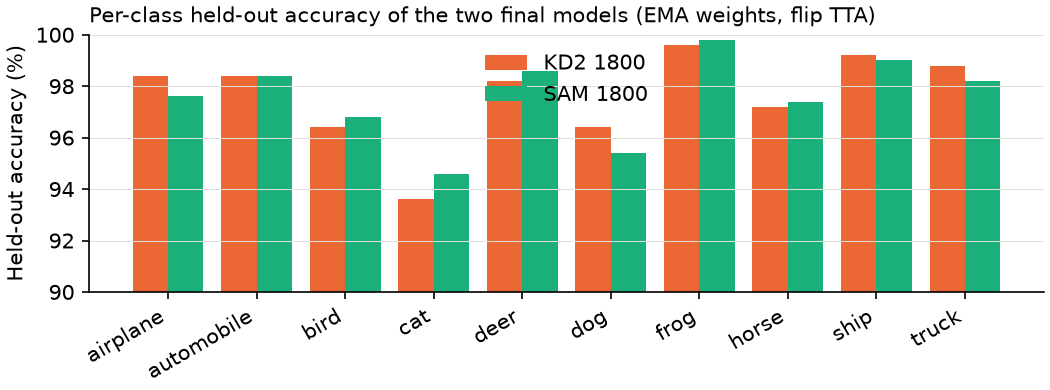

In [9]:
import matplotlib.pyplot as plt  # noqa: E402

if per_class:
    fig, ax = plt.subplots(figsize=(7, 2.6), layout="constrained")
    x = np.arange(10)
    width = 0.8 / len(per_class)
    for i, (key, values) in enumerate(per_class.items()):
        ax.bar(x + (i - (len(per_class) - 1) / 2) * width, 100 * values, width, label=key, color=("#eb6834", "#1baf7a")[i])
    ax.set_xticks(x, CLASSES, rotation=30, ha="right")
    ax.set_ylim(90, 100)
    ax.set_ylabel("Held-out accuracy (%)")
    ax.set_title("Per-class held-out accuracy of the two final models (EMA weights, flip TTA)", loc="left", fontsize=10)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.5)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

## Every number in the report's tables, checked against the published training logs

`report/figures/data/experiments.csv` holds the held-out accuracy and the A100 training-step hours of every completed
run; its `source` column names the run each number comes from. Those runs are published as `runs/hpc/<name>/` (cluster)
and `runs/<name>/` (laptop) with their per-epoch `metrics.jsonl`. Below, each row is recomputed from the log: the
flip-TTA accuracy of the EMA weights at the last epoch and the sum of the logged training-step seconds. Two rows differ by
one held-out image between the cloud log and the re-evaluation of the retrieved checkpoint on the laptop, and the report
uses the laptop value in both cases: CE 2300 seed 2027 (log 97.52%, laptop 97.54%) and the CE 1000 control run (log
97.64%, laptop 97.62%). Hours agree to within rounding except TA 400 seed 2027 (0.43 in the file, 0.451 in the log).

In [10]:
SCREENING = {("TA 400", "2026"): "r2-ta400-s2026", ("TA 400", "2027"): "r2-ta400-s2027", ("AA 400", "2026"): "r2-aa400-s2026",
             ("AA 400", "2027"): "r2-aa400-s2027", ("RA 400", "2026"): "r2-ra400-s2026", ("RA 400", "2027"): "r2-ra400-s2027",
             ("HighRes 400", "2026"): "r2-highres400-s2026", ("HighRes 400", "2027"): "r2-highres400-s2027",
             ("PreAct 400", "2026"): "r2-preact400-s2026", ("PreAct 400", "2027"): "r2-preact400-s2027",
             ("CE 1800", "2027"): "r2-ta1800-s2027", ("AA 1800", "2026"): "r2-aa1800-s2026"}


def run_directory(row):
    source = row["source"]
    if "cloud-evidence" in source or "screening" in source:
        return ROOT / "runs/hpc" / SCREENING[(row["label"], row["seed"])]
    name = source.split(" ")[0].rstrip("/").split("/")[-1]
    return ROOT / ("runs/hpc" if source.startswith("project1-hpc") else "runs") / name


def log_summary(directory):
    metrics = [json.loads(line) for line in (directory / "metrics.jsonl").read_text().splitlines() if line.strip()]
    last = metrics[-1]
    return 100 * last["tta_valid_accuracy"], math.fsum(r["train_seconds"] for r in metrics) / 3600, last["epoch"]


rows = list(csv.DictReader((ROOT / "report/figures/data/experiments.csv").open()))
print(f"{'family':6s} {'label':12s} {'seed':>4s} {'dev':5s} {'run':30s} {'heldout csv':>11s} {'from log':>8s} {'diff':>6s} {'A100h csv':>9s} {'from log':>8s}")
mismatches = []
for row in rows:
    directory = run_directory(row)
    accuracy, hours, last_epoch = log_summary(directory)
    diff = accuracy - float(row["heldout"])
    hours_text = f"{hours:8.3f}" if row["device"] == "a100" else "   (mps)"
    print(f"{row['family']:6s} {row['label']:12s} {row['seed']:>4s} {row['device']:5s} {directory.relative_to(ROOT).as_posix():30s} "
          f"{float(row['heldout']):11.2f} {accuracy:8.2f} {diff:+6.2f} {row['a100_hours'] or '':>9s} {hours_text}")
    if abs(diff) > 1e-9 or (row["a100_hours"] and abs(hours - float(row["a100_hours"])) > 0.01):
        mismatches.append((row["label"], row["seed"], round(diff, 2), row["a100_hours"], round(hours, 3)))
print(f"\n{len(rows)} rows checked; rows that differ from the log by more than rounding: {mismatches}")

family label        seed dev   run                            heldout csv from log   diff A100h csv from log
plain  CE 100       2026 mps   runs/improved100-resnet20-x4         96.72    96.72  +0.00              (mps)
plain  CE 400       2026 mps   runs/x4-400ep-45k                    97.28    97.28  +0.00              (mps)
plain  CE 400       2026 a100  runs/hpc/cloud-x4-400-s2026          97.24    97.24  +0.00     0.404    0.404
plain  TA 400       2026 a100  runs/hpc/r2-ta400-s2026              97.36    97.36  +0.00     0.430    0.430
plain  TA 400       2027 a100  runs/hpc/r2-ta400-s2027              97.32    97.32  +0.00      0.43    0.451
plain  CE 800       2026 a100  runs/hpc/cloud-x4-800-s2026          97.30    97.30  +0.00     0.822    0.822
plain  CE 800       2027 a100  runs/hpc/cloud-x4-800-s2027          97.50    97.50  +0.00     0.840    0.840
plain  CE 1000      2026 a100  runs/hpc/cloud-x4-1000-s2026         97.54    97.54  +0.00     1.030    1.030
plain  CE 1000     

## The report's figures, drawn from the data files with the report's own code

`report/figures/make_results_figures.py` produces Figures 2-5 of the report from `report/figures/data/`. The same functions
are called here (into a temporary folder, so the committed figure files are left untouched) and the results are shown
inline.

**Schedule length and cost.** (a) Held-out accuracy of every completed run against the length of its cosine schedule: the
plain recipe gains about 0.9 points from 100 to 1,800 epochs and then saturates (2,300 and 3,000 epochs do not help);
distillation, SAM, the other augmentation policies and the other layouts all land within about one standard error (0.22
points, the bar) of the plain recipe at equal length. (b) The same accuracies against measured A100 training-step hours;
the hollow markers add the time spent training the distillation teachers, which removes the small advantage of KD.

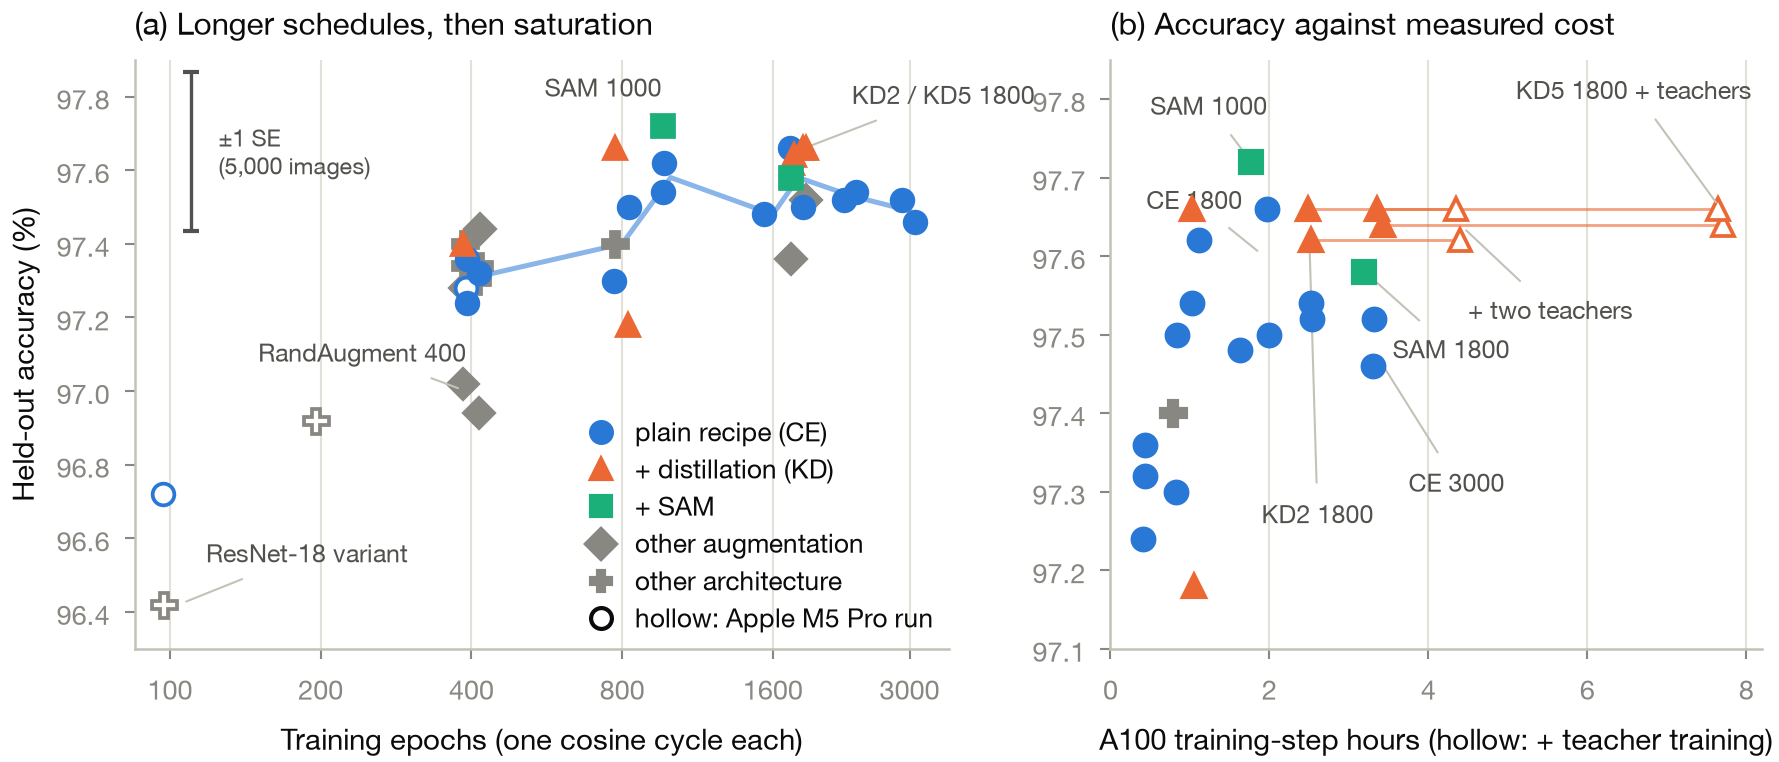

In [11]:
import importlib  # noqa: E402

sys.path.insert(0, str(ROOT / "report/figures"))
figures = importlib.import_module("make_results_figures")
figures.HERE = Path(tempfile.mkdtemp())  # output folder of the figure functions; their data folder stays report/figures/data
figures.schedule_figure()
display(Image(filename=figures.HERE / "schedule.png"))

**Training curves of the three 1,800-epoch seed-2026 runs** (plain, KD2, SAM). (a) Held-out accuracy of the EMA weights
with flip TTA, evaluated every ten epochs; (b) the last 800 epochs; (c) accuracy on the augmented training batches. The
three curves are indistinguishable for the first 1,500 epochs and all gain about half a point in the last 300 as the
learning rate decays to zero. Training-batch accuracy ends at 93-94%, four points below the held-out accuracy: the strong
augmentation remains the dominant regularizer to the end.

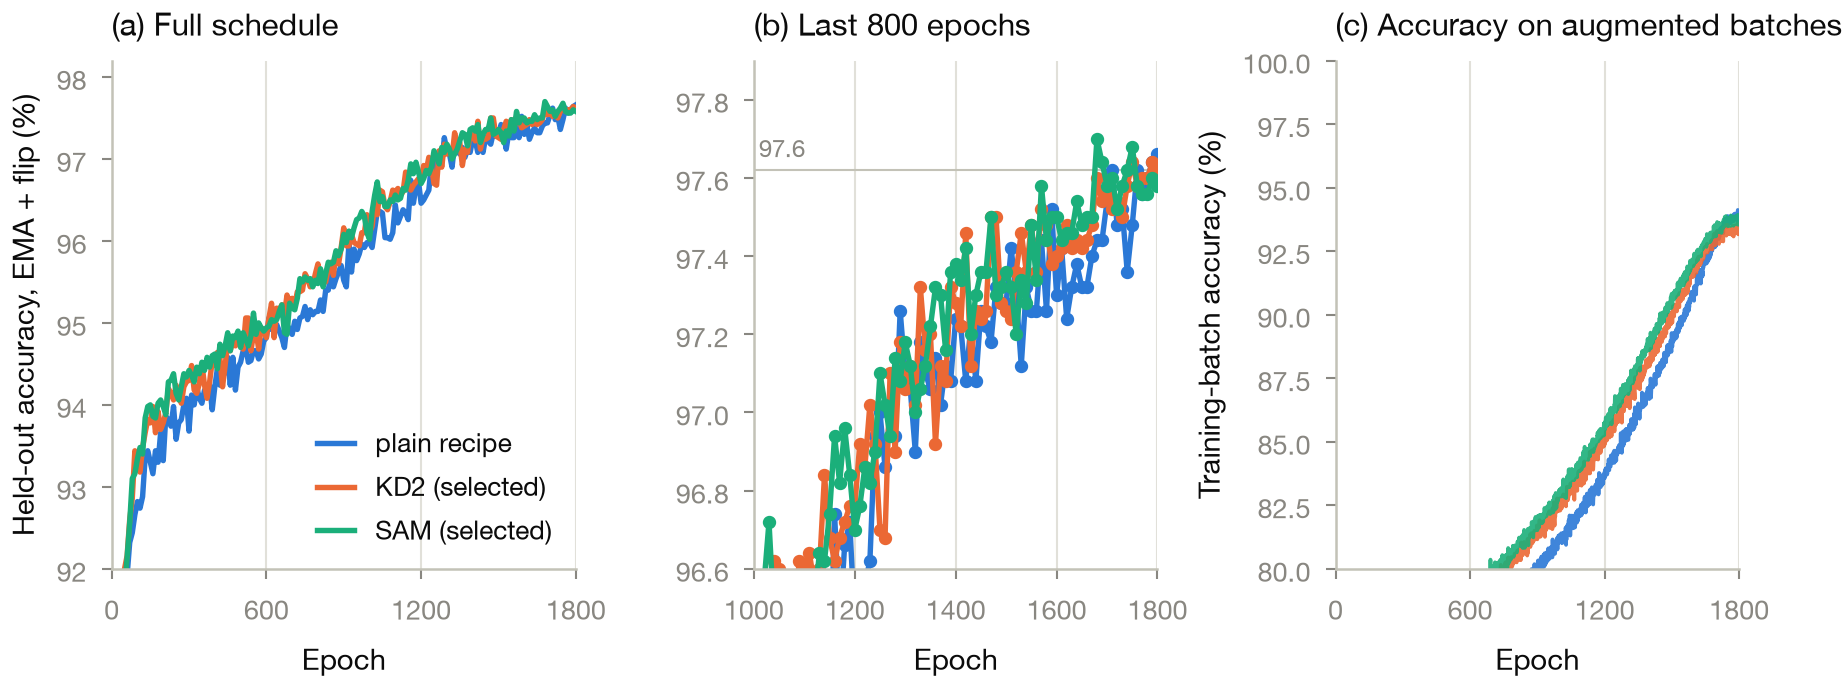

In [12]:
figures.curves_figure()
display(Image(filename=figures.HERE / "curves.png"))

**Held-out accuracy predicts the public leaderboard.** For the 19 submissions with a held-out score, the public score
(1,000 hidden test images) is plotted against the held-out accuracy (5,000 images); error bars are one binomial standard
error on each axis. The two agree up to sampling noise (slope about 1.7, r = 0.93); the hidden test images are about 8
points harder than the held-out split. The two outlined points are the final submissions.

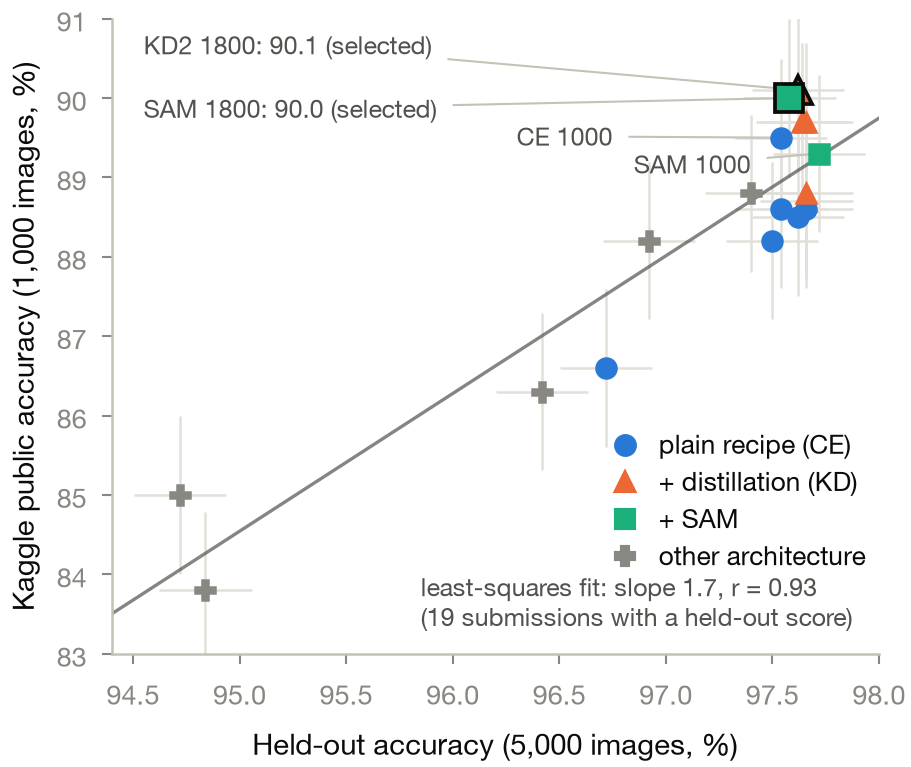

least-squares fit over the 19 scored submissions: public = 1.73 x held-out -80.2, r = 0.93


In [13]:
slope, intercept, correlation = figures.scatter_figure()
display(Image(filename=figures.HERE / "scatter.png"))
print(f"least-squares fit over the 19 scored submissions: public = {slope:.2f} x held-out {intercept:+.1f}, r = {correlation:.2f}")

**Confusion matrix of the KD2 model on the held-out split** (EMA weights, flip TTA). Diagonal cells show the per-class
accuracy in percent; off-diagonal cells show error counts out of 500 images per class. Cat (93.6%) is the hardest class and
cat-dog confusions make up 33 of the 119 errors; frog and ship are nearly solved.

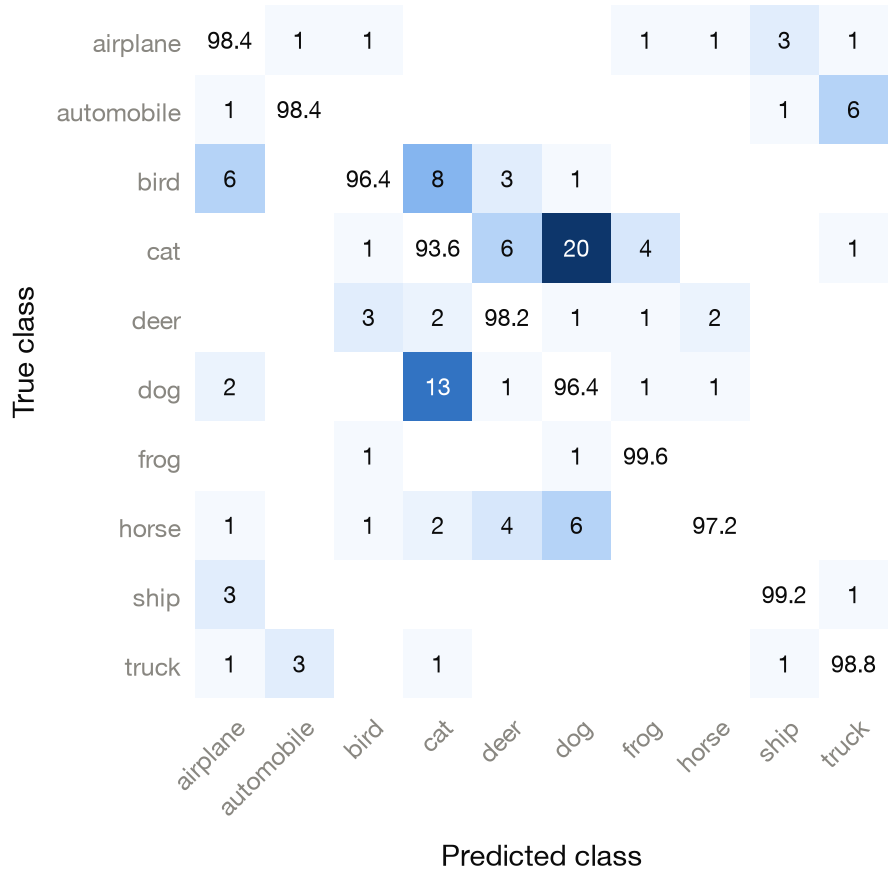

In [14]:
figures.confusion_figure()
display(Image(filename=figures.HERE / "confusion.png"))

## Kaggle submissions and the final test accuracy

One receipt was recorded per upload (`artifacts/kaggle_submissions.jsonl`, 21 uploads): the CSV hash, the checkpoint, the
held-out accuracy of the uploaded weights and the public score that Kaggle returned. The public score is Kaggle's accuracy
on the public half (1,000 images) of the hidden test set; the private half decides the final ranking and is released only
after the competition closes. Kaggle scores a team on its two selected submissions; ours are the two highest public
scores, the KD2 and SAM models above.

In [15]:
submissions = load_submissions()
print(f"{'ref':>9s} {'uploaded':10s} {'model':16s} {'params':>9s} {'train':>6s} {'held-out':>8s} {'public':>7s} {'private':>8s}  file")
for r in submissions:
    held_out = f"{100 * r['local_heldout_valid_accuracy']:.2f}" if r["local_heldout_valid_accuracy"] is not None else "(50k)"
    private = f"{100 * r['private_score']:.1f}" if r["private_score"] is not None else "pending"
    marker = " <- final" if r["submission_ref"] in {item["receipt"] for item in FINAL.values()} else ""
    print(f"{r['submission_ref']:>9d} {r['submitted_utc'][:10]:10s} {r['arch']:16s} {r['parameter_count']:>9,} {r.get('train_images') or 45000:>6,} "
          f"{held_out:>8s} {100 * r['public_score']:>7.1f} {private:>8s}  {Path(r['file']).parent.name}{marker}")

      ref uploaded   model               params  train held-out  public  private  file
 57784806 2026-10-29 resnet18-64-352  4,797,002 45,000    96.42    86.3  pending  improved100-resnet18-64-352
 57795098 2026-10-30 resnet18-64-352  4,797,002 45,000    (50k)    87.8  pending  final-resnet18-64-352-50k
 57795621 2026-10-30 resnet18-w32     2,797,610 45,000    94.84    83.8  pending  baseline-100ep
 57799551 2026-10-30 resnet18-w32     2,797,610 45,000    94.72    85.0  pending  improved100-resnet18-w32
 57799552 2026-10-30 resnet20-x4      4,327,754 45,000    96.72    86.6  pending  improved100-resnet20-x4
 57799554 2026-10-30 resnet18-64-352  4,797,002 45,000    96.92    88.2  pending  final-resnet18-64-352-45k
 57858707 2026-11-01 resnet20-x4      4,327,754 45,000    97.66    88.7  pending  cloud-kd-x4-800-s2026
 57858708 2026-11-01 resnet20-x4      4,327,754 45,000    97.54    89.5  pending  cloud-x4-1000-s2026
 57858710 2026-11-01 resnet20-x4      4,327,754 45,000    97.50    88.2

In [16]:
final_parameters = parameter_count(build_model("resnet20-x4"))
print("FINAL TEST ACCURACY (Kaggle public leaderboard, 1,000 hidden test images):")
for key, item in FINAL.items():
    r = receipts[item["receipt"]]
    assert r["parameter_count"] == final_parameters and r["arch"] == "resnet20-x4"
    private = "not yet released" if r["private_score"] is None else f"{100 * r['private_score']:.1f}%"
    print(f"    {key} ({item['run']}, submission {r['submission_ref']}): {100 * r['public_score']:.1f}%   "
          f"held-out {100 * r['local_heldout_valid_accuracy']:.2f}%   private score: {private}")
print(f"NUMBER OF TRAINABLE PARAMETERS: {final_parameters:,} (resnet20-x4; limit 5,000,000)")
print("Public leaderboard position of the best score (90.1%) on 2026-11-06 at 16:33 UTC: 21st of 64 teams "
      "(median team 89.4%, top-20% cut 90.8%). The private-leaderboard scores are released after the competition closes.")

FINAL TEST ACCURACY (Kaggle public leaderboard, 1,000 hidden test images):
    KD2 1800 (r2-kd2-ta1800-s2026, submission 57959285): 90.1%   held-out 97.62%   private score: not yet released
    SAM 1800 (sam-x4-1800-s2026, submission 58002253): 90.0%   held-out 97.58%   private score: not yet released
NUMBER OF TRAINABLE PARAMETERS: 4,327,754 (resnet20-x4; limit 5,000,000)
Public leaderboard position of the best score (90.1%) on 2026-11-06 at 16:33 UTC: 21st of 64 teams (median team 89.4%, top-20% cut 90.8%). The private-leaderboard scores are released after the competition closes.
